In [1]:
import numpy as np, torch
import CGTN_torchdata as D
from CGTN_torchmodels import HeteroGT

SLOPE="../data/constructs/sledG_torch_pitedge_pitpit_2010.npz"
BASIN="../data/constructs/basin_mushgraph2010.npz"
LINKS="../data/constructs/pit_basin_links2010.npz"
dev="cuda" if torch.cuda.is_available() else "cpu"

A=D.load_artifacts(SLOPE,BASIN,LINKS); N_s,N_b=A["N_s"],A["N_b"]; N=N_s+N_b
edges=D.build_edges(A,"full").to(dev); x_s,x_b=A["x_s"].to(dev),A["x_b"].to(dev)

m=HeteroGT(x_s.shape[1], x_b.shape[1], heads=4, layers=4).to(dev)
m.load_state_dict(torch.load("../results/ckpt/GTN_full_s0.pt", map_location=dev)["state"]); m.eval()
with torch.no_grad():
    _, (ei_att, alpha) = m(x_s, x_b, edges, return_attn=True)
ei_att=ei_att.cpu().numpy(); alpha=alpha.mean(1).cpu().numpy()      # mean over heads (last layer)

# typed edge sets -> undirected integer keys
bg=np.load(BASIN,allow_pickle=True); be,bt=bg["edge_index"],bg["edge_type"]
pl=np.load(LINKS,allow_pickle=True); pit=A["pit_torch"].numpy()
cross=np.stack([pit[pl["link_pit"]], pl["link_basin"]+N_s])
def canon(e):
    u=np.minimum(e[0],e[1]).astype(np.int64); v=np.maximum(e[0],e[1]).astype(np.int64)
    return u*np.int64(N)+v
typed={"tree":canon(A["e_tree"].numpy()), "pit-skip":canon(A["e_pitskip"].numpy()),
       "pit-pit":canon(A["e_pitpit"].numpy()),
       "basin-intra":canon(be[:,bt==0]+N_s), "basin-inter":canon(be[:,bt==1]+N_s),
       "pit→basin":canon(cross)}
ak=canon(ei_att); label=np.full(ak.size,"other",dtype=object)
for n,ks in typed.items(): label[np.isin(ak,ks)]=n
print({n:int((label==n).sum()) for n in list(typed)+["other"]})

{'tree': 1701444, 'pit-skip': 1702680, 'pit-pit': 1454, 'basin-intra': 791160, 'basin-inter': 199736, 'pit→basin': 48024, 'other': 0}


pit attention share to basin: mean 0.216 | median 0.148 | max 0.706


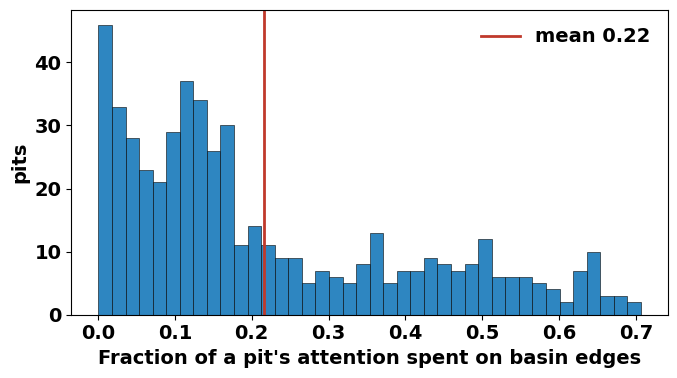

In [13]:
# Set global font size and bold weight
plt.rcParams.update({
    'font.size': 14,
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'figure.titleweight': 'bold'
})

tgt=ei_att[1]
to_pit_basin = np.isin(ak, typed["pit→basin"]) & np.isin(tgt, pit)   # basin→pit direction
frac=np.zeros(N); np.add.at(frac, tgt[to_pit_basin], alpha[to_pit_basin])
pit_frac=frac[pit]                                                    # per-pit share spent on basin
print(f"pit attention share to basin: mean {pit_frac.mean():.3f} | median {np.median(pit_frac):.3f} | max {pit_frac.max():.3f}")

import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(7,4))
ax.hist(pit_frac, bins=40, color="#2e86c1", edgecolor="k", lw=0.4)
ax.axvline(pit_frac.mean(), color="#c0392b", lw=2, label=f"mean {pit_frac.mean():.2f}")
ax.set_xlabel("Fraction of a pit's attention spent on basin edges"); ax.set_ylabel("pits")
# ax.set_title("How much each pit actually listens to the basin"); 
ax.legend(frameon=False)
plt.tight_layout()
# plt.savefig("../figures/fig3a_pit_basin_attention.png", dpi=220, bbox_inches="tight")
plt.show()

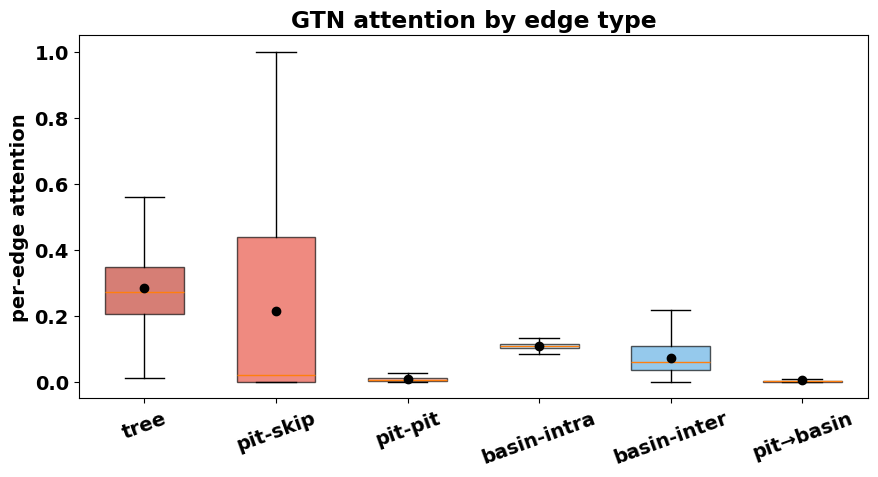

means: {'tree': np.float32(0.2853), 'pit-skip': np.float32(0.2151), 'pit-pit': np.float32(0.0099), 'basin-intra': np.float32(0.1075), 'basin-inter': np.float32(0.0739), 'pit→basin': np.float32(0.0044)}


In [14]:
plt.rcParams.update({
    'font.size': 14,
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'figure.titleweight': 'bold'
})

order=["tree","pit-skip","pit-pit","basin-intra","basin-inter","pit→basin"]
groups=[alpha[label==n] for n in order]; means=[g.mean() for g in groups]
cols=["#c0392b","#e74c3c","#f1948a","#aed6f1","#5dade2","#8e44ad"]
fig,ax=plt.subplots(figsize=(9,5))
bp=ax.boxplot(groups, positions=range(len(order)), widths=0.6, showfliers=False, patch_artist=True)
for p,c in zip(bp["boxes"],cols): p.set_facecolor(c); p.set_alpha(0.65)
ax.scatter(range(len(order)), means, c="k", zorder=5, label="mean")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=20)
ax.set_ylabel("per-edge attention")
ax.set_title("GTN attention by edge type"); 
#ax.legend(frameon=False)
plt.tight_layout()
#plt.savefig("../figures/fig3b_attention_by_type.png", dpi=220, bbox_inches="tight")
plt.show()
print("means:", {n:round(mu,4) for n,mu in zip(order,means)})

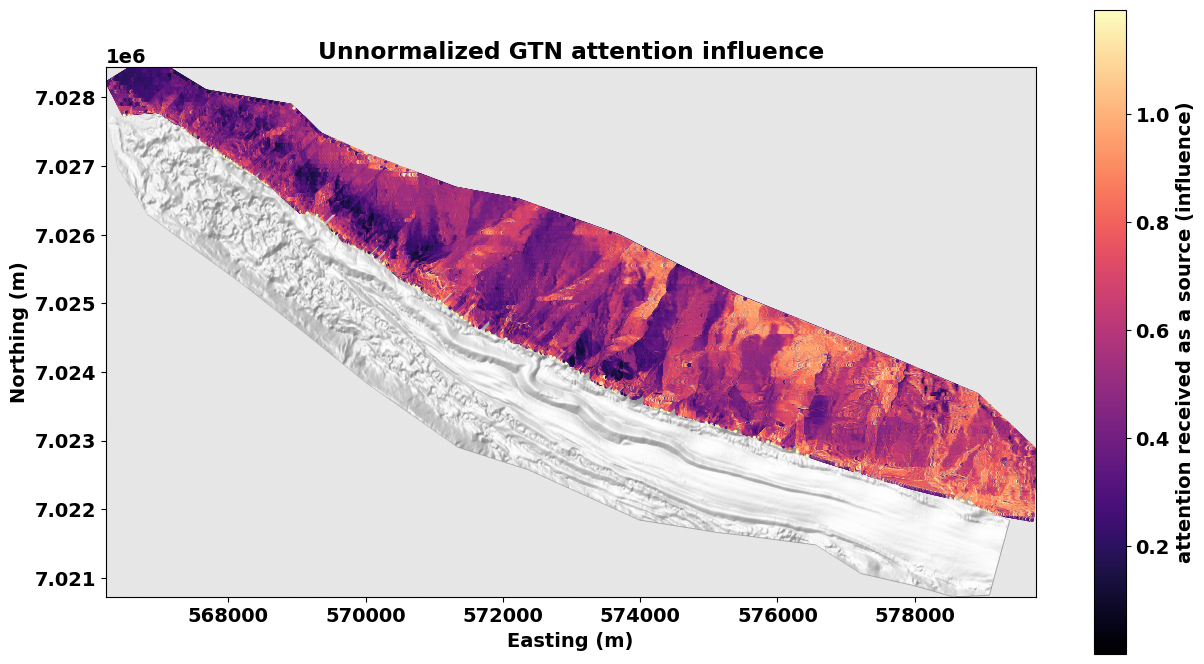

In [15]:
 # heatmap

import rasterio, numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import LightSource

influence = np.zeros(N)
np.add.at(influence, ei_att[0], alpha)     # alpha on edges where node is the SOURCE
infl = influence[:N_s]                      # slope nodes (aligned with node_rc)

DEM="../data/rasters/canwell_domainlong_elev2010_5m.tif"
with rasterio.open(DEM) as src:
    dem=src.read(1).astype(float); T=src.transform; H,W=dem.shape
dem[dem<-1e30]=np.nan
extent=(T.c, T.c+W*T.a, T.f+H*T.e, T.f)
hs=LightSource(315,45).hillshade(np.nan_to_num(dem, nan=np.nanmin(dem)), vert_exag=2)

node_rc=A["node_rc"]
xy=np.c_[T.c+(node_rc[:,1]+0.5)*T.a, T.f+(node_rc[:,0]+0.5)*T.e]
vmax=np.percentile(infl, 99)

fig,ax=plt.subplots(figsize=(13,7))
ax.imshow(hs, cmap="gray", extent=extent, origin="upper", alpha=0.55)
sc=ax.scatter(xy[:,0], xy[:,1], c=np.clip(infl,0,vmax), cmap="magma", s=2)
plt.colorbar(sc, ax=ax, label="attention received as a source (influence)")
ax.set_title("Unnormalized GTN attention influence")
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
plt.tight_layout()
#plt.savefig("../figures/fig_influence_map_nonnorm.png", dpi=220, bbox_inches="tight")
plt.show()

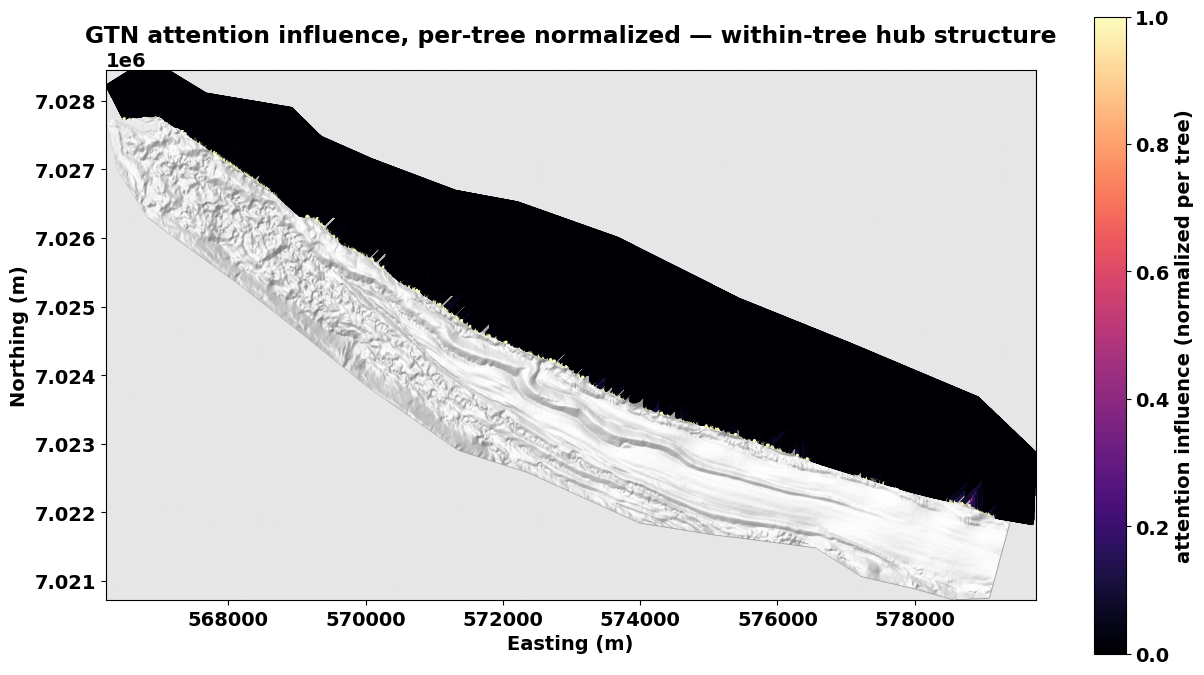

In [11]:
node_pit = np.load(SLOPE, allow_pickle=True)["node_pit_idx"]   # tree id per slope node
infl = influence[:N_s]

uniq, inv = np.unique(node_pit, return_inverse=True)           # compact tree index per node
tree_max = np.zeros(uniq.size); np.maximum.at(tree_max, inv, infl)
infl_norm = infl / (tree_max[inv] + 1e-12)                     # 0..1 within each tree

fig, ax = plt.subplots(figsize=(13, 7))
ax.imshow(hs, cmap="gray", extent=extent, origin="upper", alpha=0.55)
sc = ax.scatter(xy[:,0], xy[:,1], c=infl_norm, cmap="magma", vmin=0, vmax=1, s=2)
plt.colorbar(sc, ax=ax, label="attention influence (normalized per tree)")
ax.set_title("GTN attention influence, per-tree normalized — within-tree hub structure")
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
plt.tight_layout(); 
#plt.savefig("../results/fig3c_influence_pertree.png", dpi=220, bbox_inches="tight"); 
plt.show()

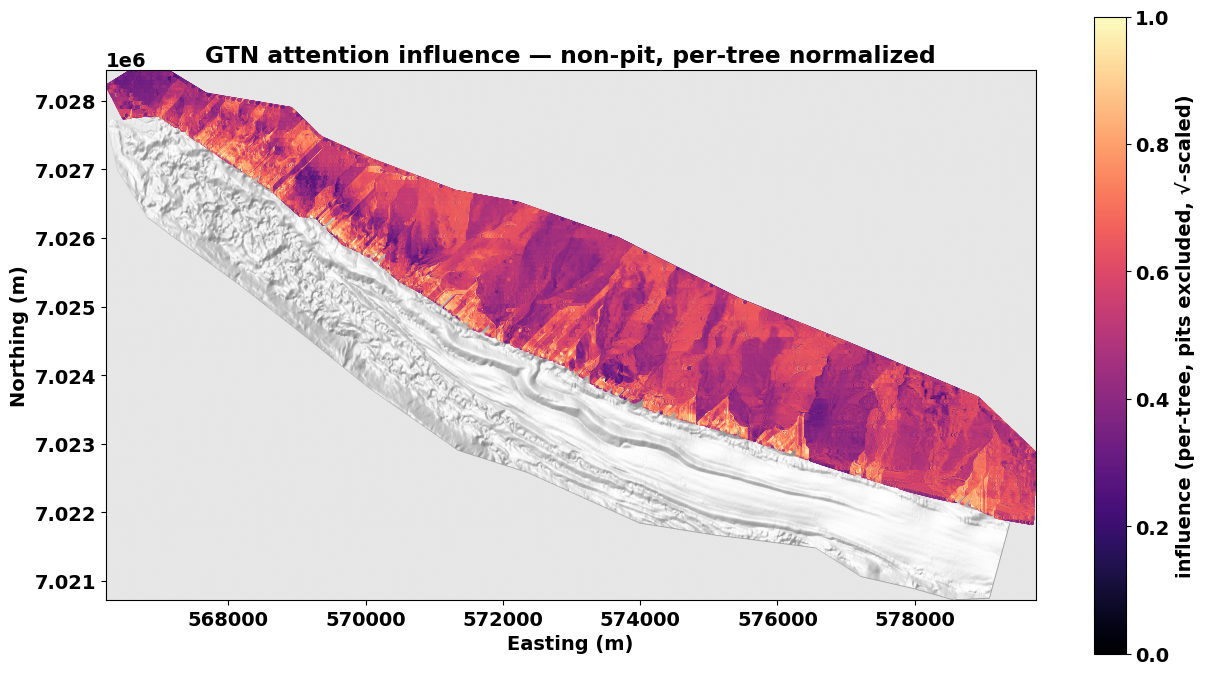

In [16]:
is_pit = (np.arange(N_s) == node_pit)
infl_np = np.where(is_pit, 0.0, infl)                       # pits don't set the ceiling
tree_max = np.zeros(uniq.size); np.maximum.at(tree_max, inv, infl_np)
norm = np.clip(infl / (tree_max[inv] + 1e-12), 0, 1)
keep = ~is_pit                                              # drop pits from the map

fig, ax = plt.subplots(figsize=(13,7))
ax.imshow(hs, cmap="gray", extent=extent, origin="upper", alpha=0.55)
sc = ax.scatter(xy[keep,0], xy[keep,1], c=norm[keep]**0.5, cmap="magma", vmin=0, vmax=1, s=2)
plt.colorbar(sc, ax=ax, label="influence (per-tree, pits excluded, √-scaled)")
ax.set_title("GTN attention influence — non-pit, per-tree normalized")
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
plt.tight_layout(); 
#plt.savefig("../figures/fig3c_influence_nopit.png", dpi=220, bbox_inches="tight"); 
plt.show()